In [2]:
from google.colab import files
import io
import os

import csv

import statsmodels.api as sm
import statsmodels.formula.api as smf
import math
from sklearn.linear_model import LinearRegression

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
from scipy import linalg as LA
import operator
from xlwt import Workbook
import xlwt

import plotly.express as px

import plotly.graph_objects as go
from plotly.subplots import make_subplots

zzz=np.random.randint(1,100)

In [3]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)
root_path = 'drive/My Drive/ECI Research/Spring 2020/Data/'

Mounted at /content/drive/


# Import Data

In [4]:
#root_path = 'drive/My Drive/ECI Research/Spring 2020/Data'

# Read input
#uploaded = files.upload()
df = pd.read_csv(root_path+'2013-2018 cleaned/2013clean.csv')
df1_cl= pd.read_csv(root_path+'2013-2018 cleaned/2013clean.csv', index_col=0)
#uploaded = files.upload()
df2 = pd.read_csv(root_path+'2013-2018 cleaned/2018clean.csv')
df2_cl= pd.read_csv(root_path+'2013-2018 cleaned/2018clean.csv', index_col=0)


In [5]:
raw_matrix = df.to_numpy()
matrix = [list(df.columns)]

for row in raw_matrix:
  if np.min(row[1::]) > 0:
    matrix.append(list(row))

raw_matrix2 = df2.to_numpy()
matrix2 = [list(df2.columns)]

for row in raw_matrix2:
  if np.min(row[1::]) > 0:
    matrix2.append(list(row))

# ECI & PCI

MCP

In [6]:
#compute mcp

def compute_mcp(matrix):
  product_list = matrix[0][1::]
  country_list = []
  for i in range(1,len(matrix)):
    country_list.append(matrix[i][0])
    
  country_sum = []
  for i in range(1,len(matrix)):
    country_sum.append(np.sum(matrix[i][1::]))
    
  product_sum = []
  for i in range(1,len(matrix[0])):
    product = 0
    for j in range(1,len(matrix)):
        product += matrix[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mcp = []
    
  for i in range (1,len(matrix)):
    country_row = []
    for j in range(1,len(matrix[i])):
      try:
        percentage = matrix[i][j]/country_sum[i-1]
      except:
        print(country_list[i-1])
      total_percentage = product_sum[j-1]/total_sum
      if percentage > total_percentage:
        country_row.append(1)
      else:
        country_row.append(0)
    mcp.append(country_row)

  return country_list,product_list,mcp,product_sum,country_sum

MCC

In [7]:
#compute mcc
def compute_mcc(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))
    
  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mcc = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp)):
      temp_sum = 0
      for k in range(0,len(mcp[0])):
        try:
          value = (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
          if np.isinf(value) or np.isnan(value):
            temp_sum += 0
          else:
            temp_sum += value
        except:
          pass
      country_row.append(temp_sum)
    mcc.append(country_row)
  return mcc

MPP

In [8]:
# compute mpp
def compute_mpp(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))
    
  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mpp = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += (mcp[k][i] * mcp2[k][j]/(country_sum[k]*product_sum[i]))
        except:
          pass
      product_row.append(temp_sum)
    mpp.append(product_row)
  return mpp

ECI

In [9]:
#compute ECI
def compute_eci(mcc):
  mcc = np.array(mcc)
    
  e_vals, e_vecs = LA.eig(mcc)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)
    
  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])
    
  eci = []
  if vector[0] < 0:
    for item in vector:
      eci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      eci.append((-item+np.mean(vector))/np.std(vector))
  return eci

PCI

In [10]:
#compute PCI
def compute_pci(mpp):
  mpp = np.array(mpp)
  e_vals, e_vecs = LA.eig(mpp)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)
    
  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])
    
  pci = []
  if vector[len(vector)-2] > 0:
    for item in vector:
      pci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      pci.append((-item+np.mean(vector))/np.std(vector))
  return pci

In [11]:
country_list,product_list,mcp,product_sum,country_sum = compute_mcp(matrix)
country_list_18,product_list_18,mcp_18,product_sum_18,country_sum_18 = compute_mcp(matrix2)

mcc = compute_mcc(mcp)
mpp = compute_mpp(mcp)

mcc_18 = compute_mcc(mcp_18)
mpp_18 = compute_mpp(mcp_18)


eci = compute_eci(mcc)
pci = compute_pci(mpp)

eci_18 = compute_eci(mcc_18)
pci_18 = compute_pci(mpp_18)

#check ECI
eci_dict = {}
for i in range(len(country_list)):
  eci_dict[country_list[i]]=eci[i]
sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))

#check PCI
pci_dict = {}
for i in range(len(product_list)):
  pci_dict[product_list[i]]=pci[i]
sorted_pci_dict = sorted(pci_dict.items(), key=operator.itemgetter(1))

#check ECI
eci_dict_18 = {}
for i in range(len(country_list_18)):
  eci_dict_18[country_list_18[i]]=eci_18[i]
sorted_eci_dict_18 = sorted(eci_dict_18.items(), key=operator.itemgetter(1))

#print(sorted_eci_dict)
for item in sorted_pci_dict:
  print(item)

('Energy Drilling and Mining', -1.5788035816446655)
('Precious Stones', -1.444343613899091)
('Vegetables, Fruits and Plants', -1.0016099820305862)
('Animals and By-products', -0.766191447980197)
('Food and Preparations', -0.7480646350544845)
('Wood Products', -0.5620112018194434)
('Clothing and Accessories', -0.5090814137773862)
('Metals', -0.33862665764738253)
('Weapons', -0.11858614962341381)
('Raw Manufacturing', 0.025188158057013545)
('Textile', 0.0828805942935162)
('Chemicals', 0.19162775357029144)
('Chemical Manufacturing', 0.2260040811507352)
('Daily Instruments', 0.4831063446699226)
('Services and Utilities ', 0.653998860193313)
('Transportation', 1.5873425369770389)
('Machinery and Construction', 1.853055871997025)
('High-complexity Products', 1.9641144825677934)


# Proximity, Distance, and RID

Proximity

In [12]:
def compute_proximity(mcp,product_sum):
  proximity = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += mcp[k][i] * mcp[k][j]
        except:
          pass
      p0 = product_sum[i]
      p1 = product_sum[j]
      if p0 < p1:
        large = p1
      else:
        large = p0
      product_row.append(temp_sum/large)
    proximity.append(product_row)
  return proximity

Distance

In [13]:
#compute distance
def compute_distance(mcp,proximity):
  distance = []
  for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
      sum1 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum1 += mcp[i][k]*proximity[j][k]
          except:
            pass
      sum2 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum2 += proximity[j][k]
          except:
            pass
      product_row.append(1-sum1/sum2)
    distance.append(product_row)
  return distance

RID

In [14]:
def compute_adi(df2,country_list,distance):
  raw_matrix = df2.to_numpy()
  matrix = [list(df2.columns)]
  for row in raw_matrix:
    if sum(row[1::]) > 0:
      matrix.append(list(row))

  country_list2,product_list2,mcp2,product_sum2,country_sum2 = compute_mcp(matrix)
  proximity2 = compute_proximity(mcp2,product_sum2)
  distance2 = compute_distance(mcp2,proximity2)

  adi = {}
  for i in range(len(country_list)):
    for j in range(len(country_list2)):
      if country_list[i] == country_list2[j]:
        adi[country_list[i]] = np.array(distance2[j]) - np.array(distance[i])
  return adi, country_list2,product_list2 

In [15]:
proximity = compute_proximity(mcp,product_sum)
proximity_18 = compute_proximity(mcp_18,product_sum_18)

distance = compute_distance(mcp,proximity)
adi, country_list2,product_list2  = compute_adi(df2,country_list,distance)

In [16]:
print(adi)

{'Bulgaria': array([-0.05656147,  0.10781709,  0.08260293,  0.05362079,  0.09987232,
       -0.00448736,  0.09543358,  0.11876785,  0.04276899,  0.0579003 ,
       -0.00403864, -0.05881344,  0.00660341,  0.09788831,  0.00554464,
        0.0473999 , -0.04144822,  0.07104513]), 'Myanmar': array([-0.01122475,  0.0008107 , -0.0012557 ,  0.01148083,  0.04331535,
        0.01204726, -0.08499633,  0.01759321, -0.01438475,  0.00319003,
        0.09903481,  0.07602243,  0.09087697,  0.04320619,  0.06412416,
       -0.0162516 ,  0.05986468, -0.05767907]), 'Burundi': array([-0.2001496 , -0.22146275, -0.04953992, -0.1227897 , -0.15564931,
       -0.18175333, -0.17334847, -0.16390731, -0.2015974 , -0.16130462,
       -0.19766996, -0.12774187, -0.08174553, -0.14447051, -0.12425716,
       -0.2170069 , -0.0856746 , -0.30312362]), 'Canada': array([-0.04701712, -0.04254934, -0.06255678, -0.05345704, -0.03865801,
       -0.07308198, -0.0476176 , -0.04503776, -0.06959114, -0.02223379,
       -0.07097157,

# Sequential Strategy

Opportunity Gain

In [17]:
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        country_row.append(gain)
      #country_row.append(gain)
    opportunity_gain.append(country_row)
    
  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

Marginal Opportunity Gain

In [18]:
def compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix):
  marginal = []
  total_sum = np.sum(product_sum)
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        export = matrix[i+1][j+1]
        country_export = country_sum[i]
        product_export = product_sum[j]
        export_increase = (product_export*country_export/total_sum)-export
        country_row.append(opportunity_gain[i][j]*export/export_increase)
    marginal.append(country_row)
    
  marginal = np.array(marginal)
  return marginal

In [19]:
opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_18,proximity_18,pci_18)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)

#for i in range(len(country_list)):
#  print(country_list[i],opportunity_gain[i])

In [20]:
# For computation of sequential strategies, refer to sequential strategy.py

In [21]:
# For sensitivity analysis, refer to sensitivity.ipynb

In [22]:
# For computation of SOI, soi.ipynb

# SDV & SIDS

In [23]:
def read_country(filename):
    f = open(filename,'r', encoding='utf-8')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                temp.append(row[i])
        raw_matrix.append(temp)  
    f.close()
    return raw_matrix

def rank(score_dict):
    rank_list = []
    score_list = []
    for item in score_dict:
        score_list.append(score_dict[item])
    while score_list:
        maximum = max(score_list)
        for item in score_dict:
            if score_dict[item] == maximum:
                rank_list.append(item)
        score_list = [score for score in score_list if score!= maximum]
    return rank_list


def sdv_and_sids(country, year):
    #Read the raw matrix
    raw_matrix = read_country(f"{year}.csv")
    raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]
    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])
    
    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))
    
    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)
    
    #print(product_list)
    #print(country_list)

    mcp = []
    
    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)
    
    #compute mpp
    country_sum2 = []
    for i in range(0,len(mcp)):
        country_sum2.append(np.sum(mcp[i]))
    
    product_sum2 = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum2.append(product)
    
    mpp = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                except:
                    pass
            product_row.append(temp_sum)
        mpp.append(product_row)
    
    #compute PCI
    mpp = np.array(mpp)
    
    e_vals, e_vecs = LA.eig(mpp)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)
    
    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])
    
    pci = []
    if vector[len(vector)-2] > 0:
        for item in vector:
            pci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            pci.append((-item+np.mean(vector))/np.std(vector))
    
    #compute proximity
    proximity = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += mcp[k][i] * mcp[k][j]
                except:
                    pass
            p0 = product_sum2[i]
            p1 = product_sum2[j]
            if p0 < p1:
                large = p1
            else:
                large = p0
            product_row.append(temp_sum/large)
        proximity.append(product_row)
    
    #compute actual distance
    distance = []
    for i in range(0,len(mcp)):
        product_row = []
        for j in range(0,len(mcp[0])):
            sum1 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum1 += (1-mcp[i][k])*proximity[j][k]
                except:
                    pass
            sum2 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum2 += proximity[j][k]
                except:
                    pass
            if mcp[i][j] == 1:
                product_row.append(0)
            else:
                product_row.append(sum1/sum2)
        distance.append(product_row)
    
    #compute opportunity gain
    opportunity_gain = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            gain = 0
            for k in range(0,len(mcp[0])):
                temp = 0
                for l in range(0,len(mcp[0])):
                    temp += proximity[l][k]
                gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
            gain = gain - (1-distance[i][j]) * pci[j]
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                country_row.append(gain)
        opportunity_gain.append(country_row)
        
    #compute marginal opportunity gain
    marginal = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                export = raw_matrix[i+1][j+1]
                country_export = country_sum[i]
                product_export = product_sum[j]
                export_increase = (product_export*country_export/total_sum)-export
                country_row.append(opportunity_gain[i][j]*country_export/export_increase)
        marginal.append(country_row)
    
    
    
    
    
    #computing sequential strategy
    strategy = []
    
    for i in range(0,len(country_list)):
        if country in country_list[i]:
            country_index = i
    og = np.copy(opportunity_gain[country_index])
    sdv = dict(zip(product_list, og))
    sdv = sorted(sdv.items(), key=operator.itemgetter(1), reverse=True)
    sdv_colors = []
    for i in range(len(sdv)):
        if sdv[i][1]>0:
          sdv_colors.append(44)
        elif sdv[i][1]==0:
          sdv_colors.append(27)
        else:
          sdv_colors.append(1)
    #print("Before Iteration: ")
    #for i in range(0,len(marginal[country_index])):
    #    print(product_list[i], ": ", marginal[country_index][i])
    #print(" ")
    
    temp = []
    temp.append("Before Iteration")
    posi = {}
    zero = []
    nega = {}
    colors = []
    color = [1]
    for i in range(0,len(marginal[country_index])):
        if marginal[country_index][i] > 0:
            posi[product_list[i]] = marginal[country_index][i]
        elif marginal[country_index][i] == 0:
            zero.append(product_list[i])
        else:
            nega[product_list[i]] = marginal[country_index][i]
    posi = rank(posi)
    nega = rank(nega)
    temp.extend(posi)
    color.extend([44 for i in range(len(posi))])
    temp.extend(zero)
    color.extend([27 for i in range(len(zero))])
    temp.extend(nega)
    color.extend([1 for i in range(len(nega))])
    strategy.append(temp)
    colors.append(color)
    
    ite_round = 0
    prev_industry = []
    
    while max(marginal[country_index]) > 0 and ite_round < 20:
        ite_round += 1
        
        value = max(marginal[country_index])
        for i in range(0,len(marginal[0])):
            if marginal[country_index][i] == value:
                industry_index = i
        industry = product_list[industry_index]
        prev_industry.append(industry_index)
        
        #calculate new export
        export = raw_matrix[country_index+1][industry_index+1]
        country_export = country_sum[country_index]
        product_export = product_sum[industry_index]
        required_export = product_export*country_export/total_sum
        export_increase = required_export-export
    
        #print("increase ", industry, " in ", country, " by ", export_increase, " USD")
    
        raw_matrix[country_index+1][industry_index+1] = required_export*1.3
        
        #calculate everything again
        country_sum = []
        for i in range(1,len(raw_matrix)):
            country_sum.append(np.sum(raw_matrix[i][1::]))
    
        product_sum = []
        for i in range(1,len(raw_matrix[0])):
            product = 0
            for j in range(1,len(raw_matrix)):
                product += raw_matrix[j][i]
            product_sum.append(product)
        total_sum = np.sum(product_sum)
    
        mcp = []
     
        for i in range (1,len(raw_matrix)):
            country_row = []
            for j in range(1,len(raw_matrix[i])):
                percentage = raw_matrix[i][j]/country_sum[i-1]
                total_percentage = product_sum[j-1]/total_sum
                if percentage > total_percentage:
                    country_row.append(1)
                else:
                    country_row.append(0)
            mcp.append(country_row)
    
        #compute mpp
        country_sum2 = []
        for i in range(0,len(mcp)):
            country_sum2.append(np.sum(mcp[i]))
    
        product_sum2 = []
        for i in range(0,len(mcp[0])):
            product = 0
            for j in range(0,len(mcp)):
                product += mcp[j][i]
            product_sum2.append(product)
    
        mpp = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                    except:
                        pass
                product_row.append(temp_sum)
            mpp.append(product_row)
    
        #compute PCI
        mpp = np.array(mpp)
    
        e_vals, e_vecs = LA.eig(mpp)
        eigenvectors = e_vecs.tolist()
        eigen = []
        for eigenvector in eigenvectors:
            temp = []
            for col in eigenvector:
                temp.append(col.real)
            eigen.append(temp)
    
        vector = []
        for i in range(0,len(eigen)):
            vector.append(eigen[i][1])
    
        pci = []
        if vector[len(vector)-2] > 0:
            for item in vector:
                pci.append((item-np.mean(vector))/np.std(vector))
        else:
            for item in vector:
                pci.append((-item+np.mean(vector))/np.std(vector))
    
        #compute proximity
        proximity = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += mcp[k][i] * mcp[k][j]
                    except:
                        pass
                p0 = product_sum2[i]
                p1 = product_sum2[j]
                if p0 < p1:
                    large = p1
                else:
                    large = p0
                product_row.append(temp_sum/large)
            proximity.append(product_row)
    
        #compute actual distance
        distance = []
        for i in range(0,len(mcp)):
            product_row = []
            for j in range(0,len(mcp[0])):
                sum1 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum1 += (1-mcp[i][k])*proximity[j][k]
                    except:
                        pass
                sum2 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum2 += proximity[j][k]
                    except:
                        pass
                if mcp[i][j] == 1:
                    product_row.append(0)
                else:
                    product_row.append(sum1/sum2)
            distance.append(product_row)
    
        #compute opportunity gain
        opportunity_gain = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                gain = 0
                for k in range(0,len(mcp[0])):
                    temp = 0
                    for l in range(0,len(mcp[0])):
                        temp += proximity[l][k]
                    gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
                gain = gain - (1-distance[i][j]) * pci[j]
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    country_row.append(gain)
            opportunity_gain.append(country_row)
        
        #compute marginal opportunity gain
        marginal = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    export = raw_matrix[i+1][j+1]
                    country_export = country_sum[i]
                    product_export = product_sum[j]
                    export_increase = (product_export*country_export/total_sum)-export
                    country_row.append(opportunity_gain[i][j]*country_export/export_increase)
            marginal.append(country_row)
        
        #print("Iteration ", ite_round, ": ")
        #for i in range(0,len(marginal[country_index])):
        #    print(product_list[i], ": ", marginal[country_index][i])
        #print(" ")
        
        temp = []
        string = "Iteration " + str(ite_round)
        temp.append(string)
        posi = {}
        zero = []
        nega = {}
        color = [1]
        for i in range(0,len(marginal[country_index])):
            if marginal[country_index][i] > 0:
                posi[product_list[i]] = marginal[country_index][i]
            elif marginal[country_index][i] == 0:
                zero.append(product_list[i])
            else:
                nega[product_list[i]] = marginal[country_index][i]
        posi = rank(posi)
        nega = rank(nega)
        temp.extend(posi)
        color.extend([44 for i in range(len(posi))])
        temp.extend(zero)
        color.extend([27 for i in range(len(zero))])
        temp.extend(nega)
        color.extend([1 for i in range(len(nega))])
        strategy.append(temp)
        colors.append(color)
    
    strategy = np.array(strategy)
    strategy = np.transpose(strategy)
    colors = np.array(colors)
    colors = np.transpose(colors)
    #print(f'color shape is {colors.shape}')

    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(strategy)):
        for j in range(len(strategy[0])):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = colors[i][j]
          sheet1.write(i,j,strategy[i][j], st)
    book.save(f'sequential strategy of {country}.xls')
    
    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(sdv)):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = sdv_colors[i]
          sheet1.write(i, 0, sdv[i][0], st)
    book.save(f'sequential vector of {country}.xls')
    print(f'{country} completed')
    
def main():
    countries = ['Brazil', 'USA', 'Mexico', 'Argentina', 'Colombia',       
               'France', 'Germany', 'Spain', 'Greece', 'Portugal', 'Italy', 'Poland',
               'Turkey', 'Saudi Arabia', 'United Arab Emirates',
               'Morocco', 'South Africa', 'Egypt', 'Nigeria', 'Rwanda', 'Tunisia', 'Ethiopia', 'Algeria',
               'China', 'Republic of Korea', 'Japan', 'Malaysia', 'Thailand', 'Singapore', 'Indonesia']
               
    for country in countries:
        sdv_and_sids(country, root_path+'2013-2018 cleaned/2013clean')

In [24]:
if __name__ == "__main__":
    main()   #Change the countries and year above to have different results

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:33: FutureWarning:

elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison



Brazil completed
USA completed
Mexico completed


UnboundLocalError: ignored

Greedy Algorithm

In [25]:
def greedy(country, year, percentage, num_part):
    df = pd.read_csv(root_path+'2013-2018 cleaned/2015clean.csv')
    raw_matrix = df.to_numpy()
    matrix = [list(df.columns)]

    for row in raw_matrix:
      if np.min(row[1::]) > 0:
        matrix.append(list(row))
    
    #print(len(raw_matrix))
    product_list = matrix[0][1::]
    #print(product_list)
    country_list = []
    for i in range(1,len(matrix)):
        country_list.append(matrix[i][0])
        if country in matrix[i][0]:
           country_index = i
           #print(country_index)
           total_export = np.sum(matrix[i][1::])
    
    budget = (percentage/100) * total_export
    print(f'Original total export is {total_export}, budget is {budget}')
    mcp = compute_mcp(matrix)[2]
    mcc = compute_mcc(mcp)
    last_eci = compute_eci(mcc)[country_index-1]
    print(f'ECI this year is {last_eci}')
    each_amount = budget/num_part
    original_vector = np.copy(matrix[country_index][1::])

    total = 0
    while total < budget:
        eci = []
        print(f'Progress: {round(total/budget, 2)}')
        for i in tqdm(range(1, len(matrix[0]))):
            matrix[country_index][i] += each_amount
            mcp = compute_mcp(matrix)[2]
            mcc = compute_mcc(mcp)
            eci.append(compute_eci(mcc)[country_index - 1])
            matrix[country_index][i] -= each_amount
        if  eci.count(max(eci)) != 1:
            #print('path 2')
            multiple = 2
            total_temp = total
            temp_each = multiple*each_amount
            while max(eci)<=last_eci and total_temp < budget:
                temp_each = multiple*each_amount
                print(f'Multiple = {multiple}, Raise each amount to {temp_each}')
                eci = []
                for i in tqdm(range(1, len(matrix[0]))):
                    matrix[country_index][i] += temp_each
                    mcp = compute_mcp(matrix)[2]
                    mcc = compute_mcc(mcp)
                    eci.append(compute_eci(mcc)[country_index - 1])
                    matrix[country_index][i] -= temp_each
                multiple += 1
                total_temp = total + temp_each
            if max(eci)<=last_eci and total_temp == budget:
               print('ECI does not change any more, add to the most adjacent ')
               export_increase = []
               mcp, product_sum, country_sum = compute_mcp(matrix)[2:]
               total_sum = np.sum(product_sum)
               for j in range(0,len(mcp[0])):
                  if mcp[country_index-1][j] == 1:
                      export_increase.append(0)
                  else:
                      export = raw_matrix[country_index][j+1]
                      country_export = country_sum[country_index-1]
                      product_export = product_sum[j]
                      export_increase.append((product_export*country_export/total_sum)-export)
               country_dist = np.array(export_increase)
               min_distance = np.where(country_dist > 0, country_dist, np.inf).argmin()
               matrix[country_index][min_distance + 1] += temp_each
            else:
               matrix[country_index][np.argmax(eci) + 1] += temp_each
               print(eci)
               print(f'After increasing, largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
               print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            total = total_temp
            last_eci = max(eci)
        else:
            #print('path 3')
            largest_component = np.argmax(eci) + 1
            print(eci)
            print(f'largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
            print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            last_eci = max(eci)
            matrix[country_index][np.argmax(eci) + 1] += each_amount
            total += each_amount
    optimal_vector = np.array(matrix[country_index][1::]) - original_vector
    max_eci = last_eci
    return dict(zip(product_list,optimal_vector)), max_eci

In [26]:
greedy('Morocco', 2015, 10, 12)

Original total export is 31004050436.0, budget is 3100405043.6000004
ECI this year is 0.4597544664749378
Progress: 0.0


NameError: ignored

# SOI

In [27]:
def read_it(filename):
    f = open(filename,'r', encoding='cp1252')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                #print(row[i])
                temp.append(row[i])
        raw_matrix.append(temp)  
    f.close()
    return raw_matrix

In [28]:
zzz+=1
def compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    # plt.scatter(independent, dependent)
                    # plt.show()
                    # print(model.cov_HC0)
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
                    
    matrix = open(root_path+"Rohan Testing/structual optimality index adi ("+str(zzz)+ ").csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in range(0,len(soi)):
       temp = [common[i],soi[common[i]]]
       writer.writerow(temp)
    matrix.close()
    return soi

In [29]:
def compute_soi_oppgain(country_list, product_list,country_list2, product_list2, opportunity_gain, opportunity_gain2):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    independent=[]
                    dependent=[]
                    for item in opportunity_gain2[j]:
                        #dependent.append([item])
                        dependent.append(item)
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    # reg = LinearRegression()
                    # reg.fit(independent, dependent)
                    # r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2

    matrix = open(root_path+"Rohan Testing/structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [30]:
def compute_soi_exp(country_list, product_list,country_list2, product_list2, opportunity_gain, exp_change):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = []
                    independent = []
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    #print(opportunity_gain2[i])
                    for item in exp_change.loc[country_list[i],:]:
                        #dependent.append([item])
                        dependent.append(item)
                    #reg = LinearRegression()
                    #reg.fit(independent, dependent)
                    #r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I':independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    soi[country_list[i]] = r_2
                    
    matrix = open(root_path+"Rohan Testing/structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [31]:
def compute_regress(soi, gdp_raw, country_list, country_list2):
    #comprehensive regression
    common=np.intersect1d(country_list, country_list2)
    independent = []
    dependent = []
    name = []
    common2= []
    growth={}
    for i in common:
        if i in gdp_raw.index.values and gdp_raw['2013'][i] != 0:
            pct_change=(float(gdp_raw['2018'][i])-float(gdp_raw['2013'][i]))/float(gdp_raw['2013'][i])
            dependent.append(pct_change)
            independent.append(soi[i])
            growth[i]=pct_change
            common2.append(i)
    # plt.scatter(independent,dependent)
    # plt.title('SOI v GDP Growth')
    # plt.xlabel('SOI')
    # plt.ylabel('% Change in GDP')
    # plt.show()
    
    # print(np.setdiff1d(common,common2))
    # print()
    # print(common)
    # print()
    # print(common2)
  
    dfs=  pd.DataFrame({'Country': common2,'GDP':dependent, 'SOI': independent})
    #dfs.set_index('Country', inplace=True)
    model = smf.ols(formula='GDP ~ SOI', data=dfs).fit()


    fig = px.scatter(dfs, x="SOI", y="GDP",  text='Country', trendline="ols") 
    fig.update_layout(
    title="Regression of GDP over SOI",
    yaxis_title="% Growth in GDP 2013-2018",
    xaxis_title="SOI",
    height=600,
    width=900,
    title_x=.5,
    font=dict(
        family="Times New Roman",
        size=15
        ) )
    #fig.update_traces(textposition='top center')
    fig.show()
    fig2 = plt.figure(figsize=(12,8))
    fig2 = sm.graphics.plot_regress_exog(model,'SOI', fig=fig2)
    fig3, ax = plt.subplots(figsize=(12,8))
    fig3 = sm.graphics.influence_plot(model, ax=ax, criterion='Cooks')
    return model, growth

In [32]:
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      country_row.append(gain)
    opportunity_gain.append(country_row)
    
  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_18,proximity_18,pci_18)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)


In [33]:

def soi_plotter(country, adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    if len(product_list) == len(product_list2):
            print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2 and country_list[i]==country:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    # print(independent)
                    # print(dependent)
                    # print(product_list)
                    # Create figure with secondary y-axis
                    fig = make_subplots(specs=[[{"secondary_y": True}]])

                    # Add traces
                    fig.add_trace(
                        go.Scatter(x=product_list, y=independent, name="Opportunity Gain"),
                        secondary_y=False,
                    )

                    fig.add_trace(
                        go.Scatter(x=product_list, y=dependent, name="ADI"),
                        secondary_y=True,
                    )

                    # Add figure title
                    fig.update_layout(
                        title_text="SOI of "+country
                    )
                    fig.update_layout(
                        height=600,
                        width=1500,
                        title_x=.5,
                        font=dict(
                            family="Times New Roman",
                            size=15
                            ) )
                    # Set x-axis title
                    fig.update_xaxes(title_text="Product Category")

                    # Set y-axes titles
                    fig.update_yaxes(title_text="RID", secondary_y=False)
                    fig.update_yaxes(title_text="Opportunity Gain", secondary_y=True)

                    fig.show()
                        
                      

SOI w/ ADI

categorization verified
                     Country Code  ...          2018
Country Name                       ...              
Afghanistan                   AFG  ...  7.267225e+10
Angola                        AGO  ...  1.990000e+11
Albania                       ALB  ...  3.830669e+10
Arab World                    ARB  ...  7.380000e+12
United Arab Emirates          ARE  ...  7.230000e+11
...                           ...  ...           ...
Kosovo                        XKX  ...  2.094114e+10
Yemen, Rep.                   YEM  ...  7.338772e+10
South Africa                  ZAF  ...  7.910000e+11
Zambia                        ZMB  ...  7.329248e+10
Zimbabwe                      ZWE  ...  4.374724e+10

[261 rows x 61 columns]


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    GDP   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.048
Method:                 Least Squares   F-statistic:                     6.177
Date:                Wed, 07 Apr 2021   Prob (F-statistic):             0.0146
Time:                        04:15:06   Log-Likelihood:                 70.696
No. Observations:                 103   AIC:                            -137.4
Df Residuals:                     101   BIC:                            -132.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.2567      0.013     19.163      0.000       0.230       0.283
SOI            0.2138      0.086      2.485      0.015       0.043       0.384
==============================================================================
Omnibus:                       20.445   Durbin-Watson:                   1.663
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               36.891
Skew:                           0.814   Prob(JB):                     9.75e-09
Kurtosis:                       5.439   Cond. No.                         7.13
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

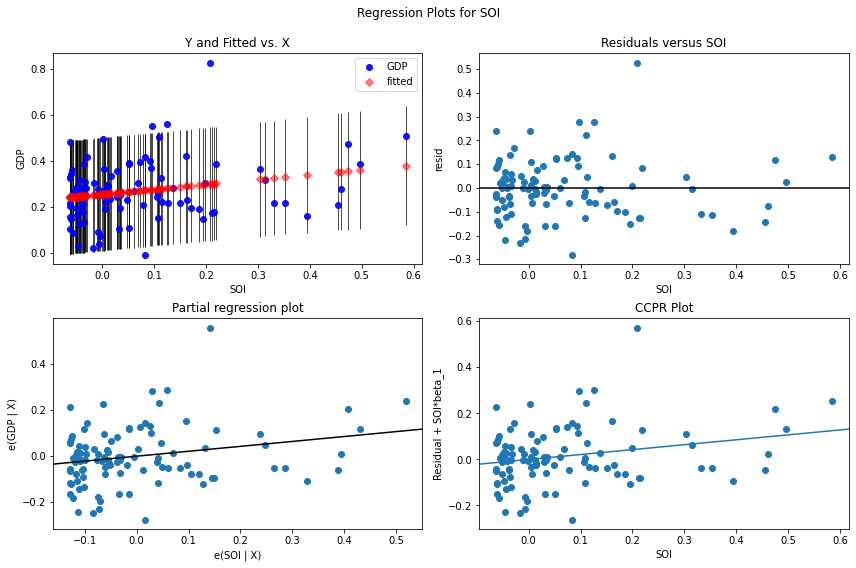

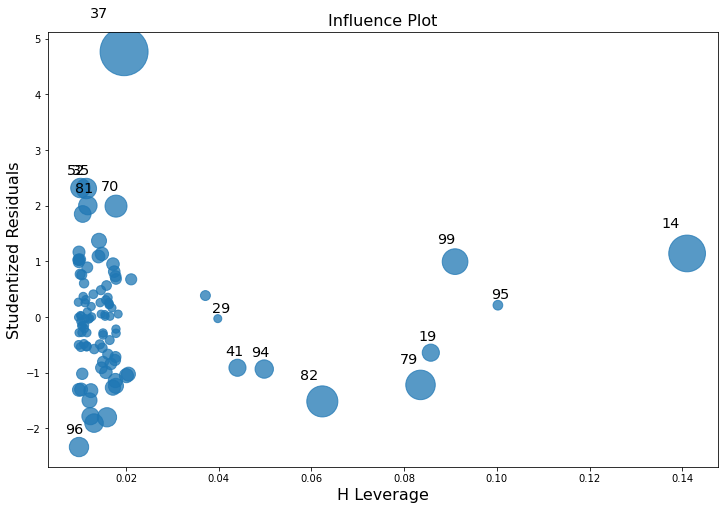

In [34]:
soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)
soi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))
gdp_raw=pd.read_csv(root_path+'GDP4.csv', index_col=0).fillna(0)
print(gdp_raw)
reg, growth= compute_regress(soi_adi, gdp_raw, country_list, country_list2)
# print(len(country_list))
# print(len(country_list2))
# print(len(soi_adi_list))
reg.summary()

In [36]:
c='China'

soi_plotter(c, adi, country_list, product_list, country_list2, product_list2, opportunity_gain)
print('SOI', soi_adi[c],'Growth', growth[c])

categorization verified


SOI 0.5846572657612421 Growth 0.5119047619047619


SOI w/ Opportunity Gain

In [ ]:
soi_oppg= compute_soi_oppgain(country_list, product_list,country_list_18, product_list_18, opportunity_gain, opportunity_gain_18)
print(sorted(soi_oppg.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_18))
reg_opp= compute_regress(soi_oppg, gdp_raw, country_list, country_list_18)
reg_opp.summary()

In [ ]:
#print(df1_cl)
#print(df2_cl)
#print(df1_cl-df2_cl)
exp_change= (df1_cl-df2_cl)/df1_cl
soi_exp= compute_soi_exp(country_list, product_list,country_list_18, product_list_18, opportunity_gain, exp_change)
print(sorted(soi_exp.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_18))
reg_exp= compute_regress(soi_exp, gdp_raw, country_list, country_list_18)
reg_exp.summary()

# End

In [ ]:
print(np.sort(list(soi_adi.keys())))
print(np.sort(country_list))
print(np.sort(country_list2))